# 13.3. US Baby Names 1880–2010

## 1. Phân tích mô tả

**Thông tin về bộ dữ liệu:**
- Dữ liệu này được thu thập từ Social Security Administration (SSA) của Hoa Kỳ.

**Đặc điểm:**
- Chỉ bao gồm các tên xuất hiện ít nhất 5 lần trong một năm để bảo vệ quyền riêng tư, tên xuất hiện ít hơn 5 lần sẽ không được ghi nhận.
- Format tên file: yobYYYY.txt

**Các cột dữ liệu**
- Tên (Name): Tên của trẻ em
- Giới tính (Sex): Nam (M) hoặc Nữ (F)
- Số lượng (Count): Số lượng trẻ được đặt tên đó trong năm


Có nhiều điều có thể làm với bộ dữ liệu này:

- Trực quan hóa tỷ lệ trẻ em được đặt một tên cụ thể (tên của bạn, hoặc tên khác) theo thời gian
- Xác định thứ hạng tương đối của một tên
- Xác định những tên phổ biến nhất trong mỗi năm hoặc những tên có độ phổ biến tăng hoặc giảm nhiều nhất
- Phân tích xu hướng trong tên: nguyên âm, phụ âm, độ dài, sự đa dạng tổng thể, thay đổi trong cách viết, chữ cái đầu và chữ cái cuối
- Phân tích các nguồn gốc bên ngoài của xu hướng: tên trong Kinh Thánh, người nổi tiếng, nhân khẩu học

In [1]:
from numpy.random import randn
import numpy as np
np.random.seed(123)
import os
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
names1880 = pd.read_csv("datasets/babynames/yob1880.txt",
                        names=["name", "sex", "births"])
names1880

,name,sex,births
0,Mary,F,7065
1,Anna,F,2604
2,Emma,F,2003
3,Elizabeth,F,1939
4,Minnie,F,1746
...,...,...,...
1995,Woodie,M,5
1996,Worthy,M,5
1997,Wright,M,5
1998,York,M,5


Để đơn giản, chúng ta có thể sử dụng tổng của cột **births** theo giới tính làm tổng số ca sinh trong năm 1880.

In [3]:
names1880.groupby("sex")["births"].sum()

sex
F     90993
M    110493
Name: births, dtype: int64

**Mục đích lấy tổng này để**:

    - Xác định tổng số ca sinh của từng giới tính trong năm → dùng làm mẫu chuẩn hóa (ví dụ: tính tỉ lệ phần trăm mỗi tên trong tổng số sinh nam/nữ).

    - Từ đó, dễ so sánh sự phổ biến tương đối của tên trong từng năm hoặc giữa các năm.

- Sử dụng prop để tính tỉ lệ phần trăm mỗi tên trong tổng số sinh theo từng giới tính.

In [4]:
# Tính tỷ lệ prop
names1880["prop"] = names1880["births"] / names1880.groupby("sex")["births"].transform("sum")
# Lọc ra giới tính nam
names_male = names1880[names1880["sex"] == "M"]
# In ra 5 dòng đầu
print(names_male.head())


        name sex  births      prop
942     John   M    9655  0.087381
943  William   M    9533  0.086277
944    James   M    5927  0.053641
945  Charles   M    5348  0.048401
946   George   M    5126  0.046392


Tên “John” đứng đầu

Có 9.655 bé trai sinh năm 1880 được đặt tên là John,

Chiếm 8.7% tổng số bé trai sinh trong năm đó.
=> Nghĩa là cứ 100 bé trai thì có gần 9 bé tên John.

Top 5 đều là những tên mang phong cách Kinh Thánh hoặc cổ điển Anh – Mỹ:
John, William, James, Charles, George.

Các tên này xuất hiện xuyên suốt trong văn hóa Anh-Mỹ suốt thế kỷ 19.

Điều này phản ánh xã hội Mỹ thời kỳ đó mang đậm nền văn hóa Thiên Chúa giáo và truyền thống châu Âu.

Chỉ 5 cái tên đã chiếm tới khoảng 32% tổng số bé trai sinh năm 1880.
(0.087 + 0.086 + 0.054 + 0.048 + 0.046 ≈ 0.32)

Nghĩa là 1/3 bé trai sinh ra đều dùng chỉ 5 cái tên phổ biến.
→ Tên thời đó rất tập trung, ít đa dạng, mọi người thích những cái tên “an toàn” và quen thuộc.

In [5]:
# Tính tỷ lệ prop
names1880["prop"] = names1880["births"] / names1880.groupby("sex")["births"].transform("sum")
# Lọc ra giới tính nam
names_male = names1880[names1880["sex"] == "F"]
# In ra 5 dòng đầu
print(names_male.head())


        name sex  births      prop
0       Mary   F    7065  0.077643
1       Anna   F    2604  0.028618
2       Emma   F    2003  0.022013
3  Elizabeth   F    1939  0.021309
4     Minnie   F    1746  0.019188


Năm 1880, có 7.065 bé gái tên “Mary”, chiếm 7.76% tổng số bé gái sinh ra.

Tên “Anna” chiếm 2.86%.

Tên “Emma” chiếm 2.20%, v.v.

-> Điều này cho thấy “Mary” là tên phổ biến nhất cho bé gái trong năm 1880.

Hợp nhất các tệp dữ liệu được chia theo năm thành một DataFrame duy nhất và thêm cột **year**

In [6]:
pieces = []
for year in range(1880, 2011):
    path = f"datasets/babynames/yob{year}.txt"
    frame = pd.read_csv(path, names=["name", "sex", "births"])

    # Add a column for the year
    frame["year"] = year
    pieces.append(frame)

# Concatenate everything into a single DataFrame
names = pd.concat(pieces, ignore_index=True)

Mục đích:

Hợp nhất toàn bộ dữ liệu nhiều năm (1880–2010) thành một tập duy nhất (names), để có thể dễ dàng:

 + Phân tích xu hướng đặt tên theo thời gian,

 + Tính độ phổ biến, tỉ lệ giới tính, sự đa dạng,

 + Xây dựng biểu đồ và mô hình long-term patterns (mô hình dài hạn).

In [7]:
names

,name,sex,births,year
0,Mary,F,7065,1880
1,Anna,F,2604,1880
2,Emma,F,2003,1880
3,Elizabeth,F,1939,1880
4,Minnie,F,1746,1880
...,...,...,...,...
1690779,Zymaire,M,5,2010
1690780,Zyonne,M,5,2010
1690781,Zyquarius,M,5,2010
1690782,Zyran,M,5,2010


Tổng hợp dữ liệu ở cấp độ **year** và **sex** bằng cách sử dụng groupby hoặc pivot_table

In [8]:
total_births = names.pivot_table("births", index="year",
                                 columns="sex", aggfunc='sum')

Tính tổng số trẻ sinh ra mỗi năm theo giới tính (nam / nữ)

→ để xem xu hướng dân số theo giới thay đổi thế nào từ năm 1880 → 2010.

In [9]:
total_births.head()

sex,F,M
year,,
1880,90993,110493
1881,91955,100748
1882,107851,113687
1883,112322,104632
1884,129021,114445


In [10]:
total_births.tail()

sex,F,M
year,,
2006,1896468,2050234
2007,1916888,2069242
2008,1883645,2032310
2009,1827643,1973359
2010,1759010,1898382


Tổng số trẻ sinh tăng gần 18 lần sau 130 năm (từ ~0.2 triệu lên ~3.6 triệu).

Tỷ lệ nam nhiều hơn nữ trong cả hai năm, nhưng chênh lệch giảm dần (từ 22% → 8%).

### Trả lời cho câu hỏi: Số lượng trẻ sinh theo giới tính thay đổi như thế nào từ 1880–2010?

<Axes: title={'center': 'Tổng số trẻ sinh theo giới tính (1880–2010)'}, xlabel='year'>

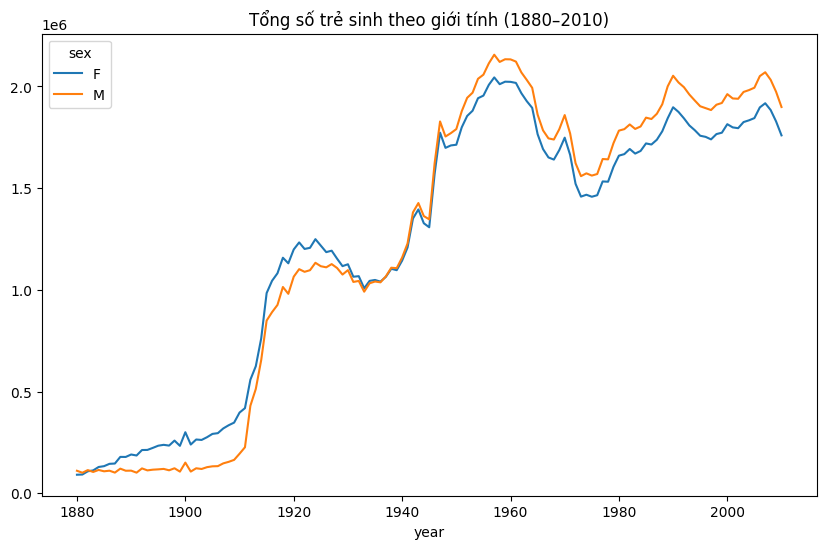

In [11]:
total_births_by_sex = names.pivot_table("births", index="year", columns="sex", aggfunc="sum")
total_births_by_sex.plot(title="Tổng số trẻ sinh theo giới tính (1880–2010)", figsize=(10,6))

Xu hướng tăng trưởng dân số

Giai đoạn đầu (1880–1940): mức sinh thấp, tăng nhẹ theo từng thập kỷ.

Sau 1940–1960: bùng nổ dân số (baby boom sau Thế Chiến II).

Từ 1980 trở đi: số ca sinh tăng mạnh, đạt đỉnh quanh 2006–2007, sau đó giảm dần đến 2010.

Giải thích khả dĩ:

Kinh tế ổn định, chăm sóc y tế tốt → tỷ lệ sinh và sống sót cao hơn.

Sau 2008, khủng hoảng kinh tế toàn cầu → nhiều cặp vợ chồng trì hoãn sinh con.

Về giới tính:

Nam giới luôn nhiều hơn nữ trong số trẻ sinh ra.

Chèn một cột **prop** với tỷ lệ của mỗi tên trẻ so với tổng số ca sinh theo nhóm dữ liệu theo **year** và **sex**:

In [12]:
def add_prop(group):
    group["prop"] = group["births"] / group["births"].sum()
    return group
names = names.groupby(["year", "sex"]).apply(add_prop)

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\2813635758.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  names = names.groupby(["year", "sex"]).apply(add_prop)


In [13]:
names

name sex  births  year      prop
year sex                                               
1880 F   0             Mary   F    7065  1880  0.077643
         1             Anna   F    2604  1880  0.028618
         2             Emma   F    2003  1880  0.022013
         3        Elizabeth   F    1939  1880  0.021309
         4           Minnie   F    1746  1880  0.019188
...                     ...  ..     ...   ...       ...
2010 M   1690779    Zymaire   M       5  2010  0.000003
         1690780     Zyonne   M       5  2010  0.000003
         1690781  Zyquarius   M       5  2010  0.000003
         1690782      Zyran   M       5  2010  0.000003
         1690783      Zzyzx   M       5  2010  0.000003

[1690784 rows x 5 columns]

Nghĩa là trong năm 1880, có 7.7% tổng số bé gái được đặt tên là Mary. Hay nói cách khác, cứ 100 bé gái thì có gần 8 bé tên Mary.

Trong năm 2010, có đúng 5 bé trai tên Zzyzx, chiếm tỷ lệ cực kỳ nhỏ — 0.0003%.

Điều này phản ánh:

 + Tên hiện đại ngày càng đa dạng (mỗi tên chiếm tỷ lệ nhỏ hơn).

 + Sự tập trung tên phổ biến đang giảm dần theo thời gian, tức là tên trở nên cá nhân hóa hơn.

Xác minh rằng cột 'prop' cộng lại bằng 1 trong tất cả các nhóm.

In [14]:
names = names.reset_index(drop=True)

In [15]:
names.groupby(["year", "sex"])["prop"].sum()

year  sex
1880  F      1.0
      M      1.0
1881  F      1.0
      M      1.0
1882  F      1.0
            ... 
2008  M      1.0
2009  F      1.0
      M      1.0
2010  F      1.0
      M      1.0
Name: prop, Length: 262, dtype: float64

Lọc dữ liệu để chỉ giữ lại 1.000 tên được đặt nhiều nhất trong mỗi nhóm **year**, **sex**.

In [16]:
def get_top1000(group):
    return group.sort_values("births", ascending=False)[:1000]
grouped = names.groupby(["year", "sex"])
top1000 = grouped.apply(get_top1000).reset_index(drop=True)  
top1000.head()

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\2711547157.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top1000 = grouped.apply(get_top1000).reset_index(drop=True)


,name,sex,births,year,prop
0,Mary,F,7065,1880,0.077643
1,Anna,F,2604,1880,0.028618
2,Emma,F,2003,1880,0.022013
3,Elizabeth,F,1939,1880,0.021309
4,Minnie,F,1746,1880,0.019188


### Trả lời cho câu hỏi: Tên nào phổ biến nhất mỗi thập kỷ (top 10 theo năm)?

In [17]:
decade = (top1000['year'] // 10) * 10
top_decade = top1000.assign(decade=decade)

births_by_decade = (
    top_decade.groupby(["decade", "sex", "name"], as_index=False)["births"]
    .sum()
)

# Lấy top 10 mỗi thập kỷ, chia theo giới tính
top10_by_decade = (
    births_by_decade.sort_values(["decade", "sex", "births"], ascending=[True, True, False])
    .groupby(["decade", "sex"])
    .head(10)
)

In [18]:
# Ví dụ xem top 10 của thập kỷ 1880
decade_to_view = 1880
top10_1980 = top10_by_decade[top10_by_decade["decade"] == decade_to_view]
print(top10_1980)


      decade sex       name  births
1018    1880   F       Mary   91672
92      1880   F       Anna   38159
463     1880   F       Emma   25404
430     1880   F  Elizabeth   25007
986     1880   F   Margaret   21800
1076    1880   F     Minnie   21724
656     1880   F        Ida   18283
171     1880   F     Bertha   18263
273     1880   F      Clara   17717
40      1880   F      Alice   17141
2392    1880   M       John   89949
3196    1880   M    William   84881
2356    1880   M      James   54058
2175    1880   M     George   47651
1818    1880   M    Charles   46658
2134    1880   M      Frank   30967
2406    1880   M     Joseph   26294
2265    1880   M      Henry   24139
2927    1880   M     Robert   24079
3075    1880   M     Thomas   23750


Thập kỷ 1880:

Tên nữ phổ biến: Mary, Anna, Emma, Elizabeth, Margaret...

Tên nam phổ biến: John, William, James, George, Charles...

Nhận xét: Các tên này mang phong cách cổ điển, thường theo truyền thống hoặc tên thánh Kinh, ít biến động qua thời gian.

In [19]:
# Ví dụ xem top 10 của thập kỷ 1980
decade_to_view = 1980
top10_1980 = top10_by_decade[top10_by_decade["decade"] == decade_to_view]
print(top10_1980)


       decade sex         name  births
27172    1980   F      Jessica  469338
27161    1980   F     Jennifer  440750
26646    1980   F       Amanda  369627
26697    1980   F       Ashley  352076
27699    1980   F        Sarah  272442
27797    1980   F    Stephanie  218070
27539    1980   F      Melissa  217856
27590    1980   F       Nicole  210410
26996    1980   F    Elizabeth  198863
27079    1980   F      Heather  191809
28805    1980   M      Michael  663241
28144    1980   M  Christopher  554565
28796    1980   M      Matthew  458687
28620    1980   M       Joshua  396406
28240    1980   M        David  383378
28515    1980   M        James  356202
28213    1980   M       Daniel  345229
28950    1980   M       Robert  321456
28599    1980   M         John  320878
28618    1980   M       Joseph  299206


Thập kỷ 1980:

Tên nữ phổ biến thường thấy: Jessica, Jennifer, Amanda, Sarah, Melissa...

Tên nam phổ biến: Michael, Christopher, Matthew, Joshua, David...

Nhận xét: Tên trong thập kỷ này mang tính hiện đại hơn, phản ánh xu hướng văn hoá và ảnh hưởng truyền thông Mỹ (phim, ca sĩ...).

In [20]:
# Ví dụ xem top 10 của thập kỷ 2000
decade_to_view = 2000
top10_1980 = top10_by_decade[top10_by_decade["decade"] == decade_to_view]
print(top10_1980)


       decade sex         name  births
32316    2000   F        Emily  223420
32793    2000   F      Madison  192914
32317    2000   F         Emma  180976
32952    2000   F       Olivia  155795
32393    2000   F       Hannah  155463
31873    2000   F      Abigail  150694
32425    2000   F     Isabella  149241
33043    2000   F     Samantha  134094
32296    2000   F    Elizabeth  133084
32035    2000   F       Ashley  132899
33779    2000   M        Jacob  273309
34128    2000   M      Michael  250031
33901    2000   M       Joshua  231482
34108    2000   M      Matthew  221163
33503    2000   M       Daniel  203294
33445    2000   M  Christopher  202899
33283    2000   M       Andrew  202110
33646    2000   M        Ethan  201552
33899    2000   M       Joseph  194238
34450    2000   M      William  193990


Đối với giới nữ (sex = F):

Những cái tên phổ biến hàng đầu thường là:

Emily, Madison, Emma, Olivia, Hannah, Abigail, Isabella, Samantha, Elizabeth, Ashley…

Nhận xét:

Các tên này mang âm điệu nhẹ nhàng, dễ phát âm, thể hiện xu hướng “ngọt ngào, hiện đại”.

Nhiều tên chịu ảnh hưởng từ văn hóa đại chúng (ví dụ: Emma và Olivia xuất hiện trong phim ảnh, sách truyện nổi tiếng).

Đặc biệt, Emily và Emma thường đứng đầu trong suốt đầu thập kỷ 2000 → chứng tỏ tính ổn định cao trong sở thích đặt tên.

Đối với giới nam (sex = M):

Tên phổ biến thường là:

Jacob, Michael, Joshua, Matthew, Christopher, Nicholas, Andrew, Daniel, Joseph, William…

Nhận xét:

Jacob là cái tên phổ biến nhất trong nhiều năm liên tiếp đầu thế kỷ XXI.

Các tên nam vẫn giữ sự ổn định truyền thống, không biến động mạnh như tên nữ.

Nhiều tên mang gốc Kinh Thánh (Jacob, Matthew, Daniel, Joseph) → cho thấy xu hướng giữ giá trị cổ điển nhưng vẫn được ưa chuộng qua nhiều thế hệ.

### Trả lời cho câu hỏi: Độ tập trung tên có thay đổi theo thời gian không (tên phổ biến chiếm bao nhiêu % tổng số sinh)?

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\673252541.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = top1000.pivot_table("prop", index="year", columns="sex", aggfunc=sum)


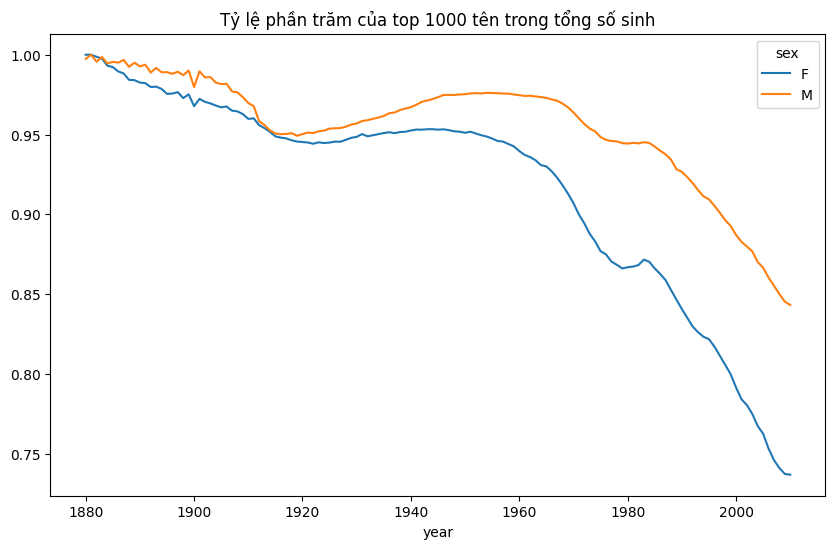

In [21]:
table = top1000.pivot_table("prop", index="year", columns="sex", aggfunc=sum)
table.plot(title="Tỷ lệ phần trăm của top 1000 tên trong tổng số sinh", figsize=(10,6))
plt.show()

Giải thích biểu đồ

Biểu đồ thể hiện tỷ lệ phần trăm số trẻ sinh ra có tên nằm trong top 1000 phổ biến nhất mỗi năm, chia theo giới tính.

Trục X: năm sinh (1880 → 2010)

Trục Y: tỷ lệ % (cao nghĩa là tên tập trung, ít đa dạng; thấp nghĩa là tên đa dạng hơn).

Xu hướng tổng quát

+ Giai đoạn 1880–1940:

Cả nam (M) và nữ (F) đều có tỷ lệ gần 100%, nghĩa là gần như tất cả trẻ sinh ra đều dùng các tên phổ biến.

→ Sự lựa chọn tên còn hạn chế, và người dân thường đặt tên “truyền thống”, phổ biến rộng rãi.

+ Giai đoạn 1940–1970:

Tỷ lệ tăng nhẹ (đặc biệt là giới nam) → Một vài cái tên chiếm tỷ lệ cao trong xã hội (ví dụ: James, John, Michael…).

Độ tập trung tên vẫn cao, thể hiện ít thay đổi trong văn hóa đặt tên.

+ Giai đoạn 1970–2010:

Cả hai giới đều giảm mạnh, đặc biệt là nữ giới giảm nhanh hơn nam giới.

Tỷ lệ của nữ từ ~95% xuống còn ~73% → cho thấy xu hướng đa dạng hóa tên.

Nam cũng giảm nhưng nhẹ hơn → chứng tỏ tên nam vẫn truyền thống hơn.

Xu hướng này gắn liền với:

Ảnh hưởng của văn hóa đại chúng (phim, ca sĩ, nhân vật nổi tiếng).

Sự tự do sáng tạo và cá nhân hóa trong cách đặt tên (đặt tên lạ, độc, có ý nghĩa riêng).

Kết luận

Độ tập trung tên giảm dần theo thời gian → xã hội ngày càng có xu hướng đa dạng hóa trong lựa chọn tên.

Giới nữ giảm nhanh hơn giới nam, phản ánh sự linh hoạt và sáng tạo hơn trong việc đặt tên cho con gái.

Hiện tượng này thể hiện sự thay đổi văn hóa và xã hội: từ truyền thống sang hiện đại, đề cao tính cá nhân và độc đáo.

## Phân tích những cái tên xu hướng

Chia top1000 ra theo giới tính

In [22]:
boys = top1000[top1000["sex"] == "M"]
girls = top1000[top1000["sex"] == "F"]

boys chứa khoảng 1000 tên phổ biến nhất mỗi năm dành cho nam.

girls chứa 1000 tên phổ biến nhất mỗi năm dành cho nữ.

Tạo một pivot table của tổng số ca sinh theo **year** và **name**

In [23]:
total_births = top1000.pivot_table("births", index="year",
                                   columns="name",
                                   aggfunc=sum)

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\4023194278.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  total_births = top1000.pivot_table("births", index="year",


Tạo ra một bảng tổng hợp (pivot table) trong đó:

 + Mỗi hàng (index) là một năm (từ 1880 đến 2010).

 + Mỗi cột (columns) là một tên (ví dụ: Mary, John, Linda, James, ...).

 + Giá trị (values) là số ca sinh có tên đó trong năm đó (sum).

<class 'pandas.core.frame.DataFrame'>
Index: 131 entries, 1880 to 2010
Columns: 6868 entries, Aaden to Zuri
dtypes: float64(6868)
memory usage: 6.9 MB


array([<Axes: xlabel='year'>, <Axes: xlabel='year'>,
       <Axes: xlabel='year'>, <Axes: xlabel='year'>], dtype=object)

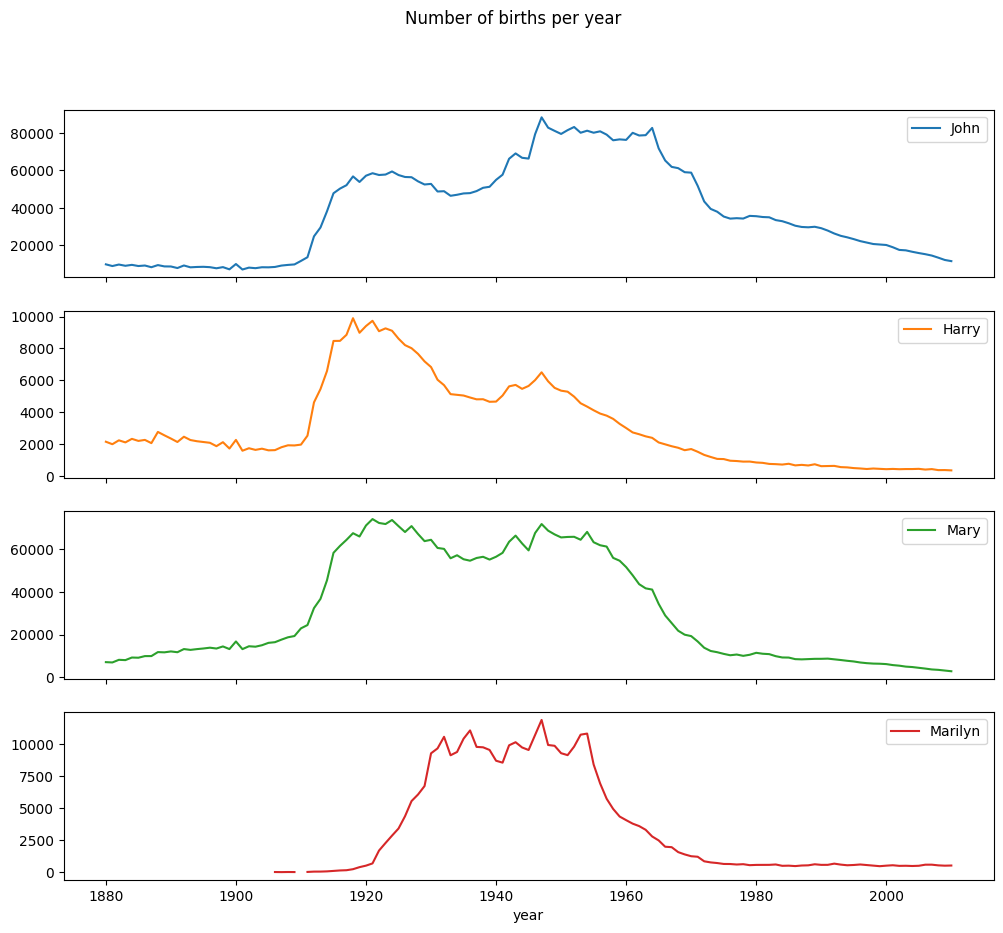

In [24]:
total_births.info()
subset = total_births[["John", "Harry", "Mary", "Marilyn"]]
subset.plot(subplots=True, figsize=(12, 10),
            title="Number of births per year")

Giải thích:

Có 131 dòng, tương ứng 131 năm (1880 → 2010).

Có 6.868 cột – mỗi cột là một tên.

Dữ liệu được tính bằng số lượng trẻ sinh mang tên đó trong từng năm.

1. Tên “John” – Biểu tượng truyền thống lâu đời

Tên John đạt đỉnh vào khoảng 1940–1955, với hơn 80.000 bé trai mang tên này mỗi năm.

Sau đó, số lượng trẻ tên John giảm mạnh, đặc biệt từ sau năm 1970.

Điều này phản ánh xu hướng xa dần các tên tôn giáo hoặc cổ điển, khi xã hội Mỹ trở nên cởi mở và đa dạng hơn về văn hóa.

2. Tên “Harry” – Sớm nở tối tàn

Tên Harry phổ biến trong giai đoạn 1910–1930, sau đó tụt dốc không phanh.

Sự suy giảm có thể liên quan đến việc Harry trở thành tên phổ biến trong tầng lớp trung niên, khiến các thế hệ sau ít sử dụng.

3. Tên “Mary” – Nữ hoàng của các tên nữ

“Mary” thống trị suốt giai đoạn 1880–1940, luôn nằm ở vị trí số 1.

Tuy nhiên, sau 1960, tên này giảm dần mạnh mẽ, nhường chỗ cho những tên mới như “Jennifer”, “Jessica”, “Emily”.

Nguyên nhân: sự đa dạng hóa văn hóa và tôn giáo ở Mỹ, cùng với mong muốn cha mẹ đặt tên mang dấu ấn riêng.

4. Tên “Marilyn” – Hiện tượng văn hóa đại chúng

“Marilyn” gần như không xuất hiện trước năm 1920, nhưng tăng vọt nhanh chóng sau năm 1930, đạt đỉnh vào 1950, đúng thời kỳ Marilyn Monroe nổi tiếng.

Sau khi nữ minh tinh qua đời (1962), tên này giảm nhanh và hiếm dần.

Khi nhìn vào đây, bạn có thể kết luận rằng những cái tên này đã không còn được ưa chuộng trong dân số Mỹ nữa. Nhưng thực tế câu chuyện phức tạp hơn thế, và sẽ được khám phá trong phần tiếp theo.

## Đo lường sự gia tăng của tính đa dạng trong đặt tên

Một lời giải thích cho sự giảm sút trong các biểu đồ là ngày càng ít phụ huynh chọn những cái tên phổ biến cho con cái của họ.

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\59272313.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = top1000.pivot_table("prop", index="year",


<Axes: title={'center': 'Sum of table1000.prop by year and sex'}, xlabel='year'>

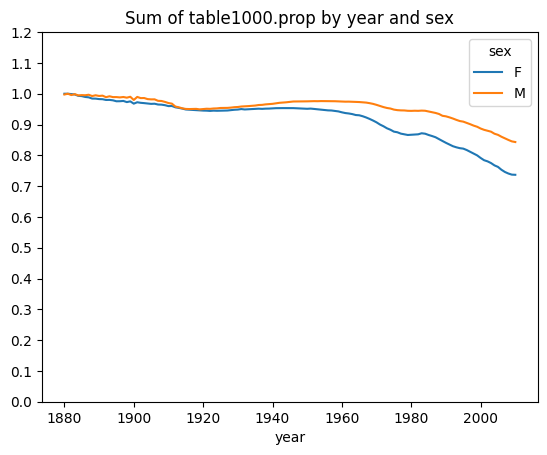

In [25]:
table = top1000.pivot_table("prop", index="year",
                            columns="sex", aggfunc=sum)
table.plot(title="Sum of table1000.prop by year and sex",
           yticks=np.linspace(0, 1.2, 13))

Tỷ lệ tổng trong một nghìn tên hàng đầu đang **giảm**.

Một chỉ số thú vị khác là: cần bao nhiêu tên khác nhau (tính từ tên phổ biến nhất) để chiếm được 50% tổng số trẻ sinh ra. Hãy cùng xem xét chỉ những cái tên con trai từ năm 2010:

In [26]:
df = boys[boys["year"] == 2010]
df

,name,sex,births,year,prop
260877,Jacob,M,21875,2010,0.011523
260878,Ethan,M,17866,2010,0.009411
260879,Michael,M,17133,2010,0.009025
260880,Jayden,M,17030,2010,0.008971
260881,William,M,16870,2010,0.008887
...,...,...,...,...,...
261872,Camilo,M,194,2010,0.000102
261873,Destin,M,194,2010,0.000102
261874,Jaquan,M,194,2010,0.000102
261875,Jaydan,M,194,2010,0.000102


Sau khi sắp xếp prop theo thứ tự giảm dần, lấy tổng tích lũy (cumsum) của prop rồi dùng searchsorted sẽ trả về vị trí cần chèn 0.5 để giữ thứ tự sắp xếp:

In [27]:
prop_cumsum = df["prop"].sort_values(ascending=False).cumsum()
prop_cumsum[:10]
prop_cumsum.searchsorted(0.5)

116

Vì mảng có chỉ số bắt đầu từ 0, nên cộng thêm 1 vào kết quả này sẽ cho bạn `117`

Ngược lại, ở năm 1900, con số này nhỏ hơn khá nhiều.

In [28]:
df = boys[boys.year == 1900]
in1900 = df.sort_values("prop", ascending=False).prop.cumsum()
in1900.searchsorted(0.5) + 1

25

Ở năm 1900, chỉ là cần `26` tên khác nhau để chiếm được 50% tổng số trẻ sinh ra.

=> Ta thấy được sự đa dạng của các tên đã tăng trưởng qua các năm

In [29]:
def get_quantile_count(group, q=0.5):
    group = group.sort_values("prop", ascending=False)
    return group.prop.cumsum().searchsorted(q) + 1

diversity = top1000.groupby(["year", "sex"]).apply(get_quantile_count)
diversity = diversity.unstack()

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\1666708627.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  diversity = top1000.groupby(["year", "sex"]).apply(get_quantile_count)


In [30]:
diversity.head()

sex,F,M
year,,
1880,38,14
1881,38,14
1882,38,15
1883,39,15
1884,39,16


<Axes: title={'center': 'Number of popular names in top 50%'}, xlabel='year'>

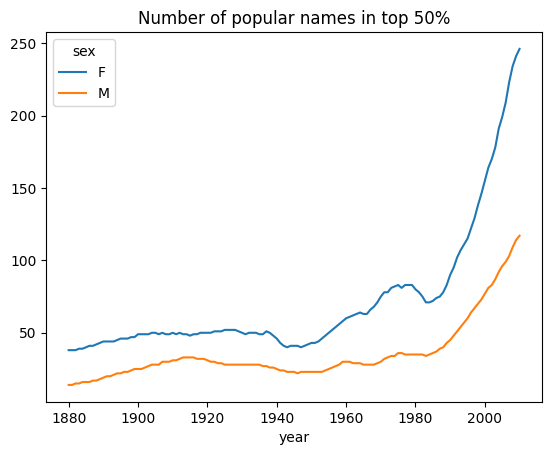

In [31]:
diversity.plot(title="Number of popular names in top 50%")

=> Tên của bé gái luôn đa dạng hơn tên của bé trai, và chúng chỉ ngày càng trở nên đa dạng hơn theo thời gian.

## Cuộc "cách mạng chữ cái cuối"

Năm 2007, nhà nghiên cứu tên trẻ sơ sinh Laura Wattenberg đã chỉ ra rằng sự phân bố tên con trai theo chữ cái cuối đã thay đổi đáng kể trong 100 năm qua. Để thấy điều này, trước tiên tổng hợp tất cả các ca sinh trong toàn bộ tập dữ liệu theo năm, giới tính và chữ cái cuối:

In [32]:
def get_last_letter(x):
 return x[-1]\

last_letters = names["name"].map(get_last_letter)
last_letters.name = "last_letter"
table = names.pivot_table("births", index=last_letters,
columns=["sex", "year"], aggfunc=sum)

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\172230162.py:6: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = names.pivot_table("births", index=last_letters,


Sau đó, chọn ba năm đại diện cho toàn bộ lịch sử và in ra một vài hàng đầu tiên:

In [33]:
subtable = table.reindex(columns=[1910, 1960, 2010], level="year")
subtable.head()

sex                 F                            M                    
year             1910      1960      2010     1910      1960      2010
last_letter                                                           
a            108376.0  691247.0  670605.0    977.0    5204.0   28438.0
b                 NaN     694.0     450.0    411.0    3912.0   38859.0
c                 5.0      49.0     946.0    482.0   15476.0   23125.0
d              6750.0    3729.0    2607.0  22111.0  262112.0   44398.0
e            133569.0  435013.0  313833.0  28655.0  178823.0  129012.0

Tiếp theo, chuẩn hóa bảng theo tổng số ca sinh để tính ra một bảng mới chứa tỉ lệ tổng số ca sinh cho mỗi giới tính kết thúc bằng mỗi chữ cái.

In [34]:
subtable.sum()
letter_prop = subtable / subtable.sum()
letter_prop

sex                 F                             M                    
year             1910      1960      2010      1910      1960      2010
last_letter                                                            
a            0.273390  0.341853  0.381240  0.005031  0.002440  0.014980
b                 NaN  0.000343  0.000256  0.002116  0.001834  0.020470
c            0.000013  0.000024  0.000538  0.002482  0.007257  0.012181
d            0.017028  0.001844  0.001482  0.113858  0.122908  0.023387
e            0.336941  0.215133  0.178415  0.147556  0.083853  0.067959
f                 NaN  0.000010  0.000055  0.000783  0.004325  0.001188
g            0.000144  0.000157  0.000374  0.002250  0.009488  0.001404
h            0.051529  0.036224  0.075852  0.045562  0.037907  0.051670
i            0.001526  0.039965  0.031734  0.000844  0.000603  0.022628
j                 NaN       NaN  0.000090       NaN       NaN  0.000769
k            0.000121  0.000156  0.000356  0.036581  0.049384  0.018541
l            0.043189  0.033867  0.026356  0.065016  0.104904  0.070367
m            0.001201  0.008613  0.002588  0.058044  0.033827  0.024657
n            0.079240  0.130687  0.140210  0.143415  0.152522  0.362771
o            0.001660  0.002439  0.001243  0.017065  0.012829  0.042681
p            0.000018  0.000023  0.000020  0.003172  0.005675  0.001269
q                 NaN       NaN  0.000030       NaN       NaN  0.000180
r            0.013390  0.006764  0.018025  0.064481  0.031034  0.087477
s            0.039042  0.012764  0.013332  0.130815  0.102730  0.065145
t            0.027438  0.015201  0.007830  0.072879  0.065655  0.022861
u            0.000684  0.000574  0.000417  0.000124  0.000057  0.001221
v                 NaN  0.000060  0.000117  0.000113  0.000037  0.001434
w            0.000020  0.000031  0.001182  0.006329  0.007711  0.016148
x            0.000015  0.000037  0.000727  0.003965  0.001851  0.008614
y            0.110972  0.152569  0.116828  0.077349  0.160987  0.058168
z            0.002439  0.000659  0.000704  0.000170  0.000184  0.001831

Nhận xét:
1. Xu hướng Tên Nữ (Female - F)

Tên kết thúc bằng 'a': Cho thấy một xu hướng tăng ổn định về mức độ phổ biến. Tỉ lệ tăng từ khoảng 27% vào năm 1910 lên 38% vào năm 2010. Điều này khẳng định sự gia tăng ưu chuộng các tên con gái kết thúc bằng nguyên âm này (ví dụ: Isabella, Olivia).

Tên kết thúc bằng 'e': Có xu hướng giảm đáng kể. Tỉ lệ giảm từ khoảng 33.7% năm 1910 xuống còn 17.8% năm 2010.

Tên kết thúc bằng 'y': Phổ biến nhất vào năm 1960 (khoảng 15%) và giảm nhẹ vào năm 2010 (khoảng 11.6%).

Tên kết thúc bằng 'h' và 'n': Cho thấy xu hướng tăng lên vào năm 2010 so với các năm trước đó.

2. Xu hướng Tên Nam (Male - M)

Tên kết thúc bằng 'n': Cho thấy xu hướng tăng trưởng mạnh mẽ nhất và là một phát hiện chính mà nhà nghiên cứu Laura Wattenberg đã chỉ ra. Tỉ lệ tăng từ 14.3% năm 1910 lên 15.2% năm 1960 và sau đó tăng vọt lên 36.2% vào năm 2010, chiếm hơn một phần ba tổng số ca sinh bé trai trong năm đó.

Tên kết thúc bằng 'd': Tỉ lệ giảm rõ rệt từ khoảng 11.4% năm 1910 (cao nhất vào năm 1960: 12.3%) xuống chỉ còn 2.3% vào năm 2010.

Tên kết thúc bằng 'y': Giống như tên nữ, phổ biến nhất vào năm 1960 (khoảng 16.1%) và giảm mạnh vào năm 2010 (khoảng 5.8%).

Với tỷ lệ chữ cái hiện có trong tay, chúng ta có thể tạo biểu đồ thanh cho từng giới tính, được chia nhỏ theo năm.

In [35]:
# Khai báo thư tviện
import matplotlib.pyplot as plt

In [36]:
print(letter_prop.columns)
print(letter_prop.index)

MultiIndex([('F', 1910),
            ('F', 1960),
            ('F', 2010),
            ('M', 1910),
            ('M', 1960),
            ('M', 2010)],
           names=['sex', 'year'])
Index(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n',
       'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z'],
      dtype='object', name='last_letter')


<Axes: title={'center': 'Female'}, xlabel='last_letter'>

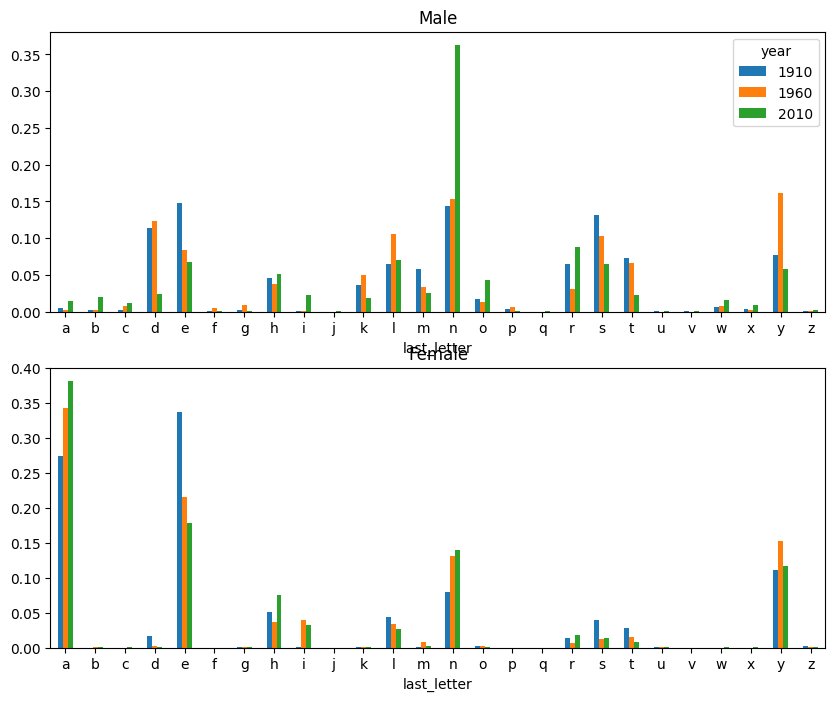

In [37]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
letter_prop["M"].plot(kind="bar", rot=0, ax=axes[0], title="Male")
letter_prop["F"].plot(kind="bar", rot=0, ax=axes[1], title="Female", legend=False)

In [38]:
plt.subplots_adjust(hspace=0.25)

<Figure size 640x480 with 0 Axes>

Như bạn có thể thấy, tên con trai kết thúc bằng n đã có sự tăng trưởng đáng kể kể từ những năm 1960. Quay lại bảng đầy đủ đã tạo trước đó, tôi lại chuẩn hóa theo năm và giới tính, rồi chọn một tập hợp con các chữ cái cho tên con trai, cuối cùng chuyển vị để biến mỗi cột thành một chuỗi thời gian:

In [39]:
letter_prop = table / table.sum()

dny_ts = letter_prop.loc[["d", "n", "y"], "M"].T
dny_ts.head()

last_letter,d,n,y
year,,,
1880,0.083055,0.153213,0.075760
1881,0.083247,0.153214,0.077451
1882,0.085340,0.149560,0.077537
1883,0.084066,0.151646,0.079144
1884,0.086120,0.149915,0.080405


In [40]:
plt.close("all")

In [41]:
fig = plt.figure()

<Figure size 640x480 with 0 Axes>

Với DataFrame chuỗi thời gian này, tôi có thể vẽ lại biểu đồ xu hướng theo thời gian một lần nữa bằng phương pháp vẽ biểu đồ

<Axes: xlabel='year'>

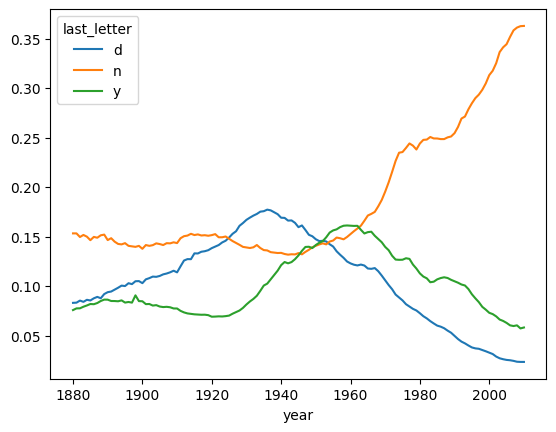

In [42]:
dny_ts.plot()

## Tên con trai trở thành tên con gái (và ngược lại)

Một xu hướng thú vị khác là xem xét những cái tên phổ biến hơn với một giới tính trước đó trong mẫu nhưng đã trở nên được ưa chuộng hơn khi dùng làm tên cho giới tính còn lại theo thời gian. Một ví dụ là tên Lesley hoặc Leslie. Quay lại với DataFrame top1000, tôi tính toán một danh sách các tên xuất hiện trong tập dữ liệu bắt đầu bằng "Lesl":

In [43]:
all_names = pd.Series(top1000["name"].unique())
lesley_like = all_names[all_names.str.contains("Lesl")]
lesley_like

632     Leslie
2294    Lesley
4262    Leslee
4728     Lesli
6103     Lesly
dtype: object

Từ đó, chúng ta có thể lọc xuống chỉ còn những tên đó và cộng các ca sinh được nhóm theo tên để xem tần suất tương đối:

In [44]:
filtered = top1000[top1000["name"].isin(lesley_like)]
filtered.groupby("name")["births"].sum()

name
Leslee      1082
Lesley     35022
Lesli        929
Leslie    370429
Lesly      10067
Name: births, dtype: int64

Tiếp theo, chúng ta hãy tổng hợp theo giới tính và năm, và chuẩn hóa trong năm:

In [45]:
table = filtered.pivot_table("births", index="year",
                             columns="sex", aggfunc="sum")
table = table.div(table.sum(axis="columns"), axis="index")
table.tail()

sex,F,M
year,,
2006,1.0,NaN
2007,1.0,NaN
2008,1.0,NaN
2009,1.0,NaN
2010,1.0,NaN


In [46]:
fig = plt.figure()

<Figure size 640x480 with 0 Axes>

Cuối cùng, bây giờ có thể tạo biểu đồ phân tích sự phân chia theo giới tính theo thời gian

<Axes: xlabel='year'>

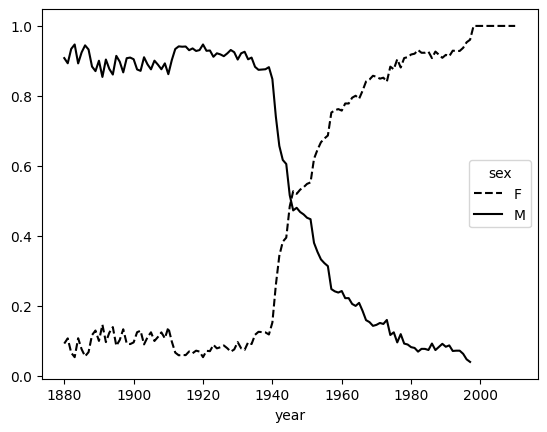

In [47]:
table.plot(style={"M": "k-", "F": "k--"})

Nhận xét:
Giai đoạn 1880-1940:

Xu hướng Tên Nam (M) - Đường liền nét: Tỉ lệ đặt tên ổn định ở mức rất cao (khoảng 85% - 95%).

Xu hướng Tên Nữ (F) - Đường nét đứt: Tỉ lệ đặt tên ổn định ở mức rất thấp (khoảng 5% - 15%).

=> Trong giai đoạn này, các tên "Lesl-" chủ yếu là tên dành cho bé trai.

Giai đoạn 1940-1970:

Xu hướng Tên Nam (M) - Đường liền nét: Tỉ lệ đặt tên giảm mạnh từ khoảng 90% xuống dưới 10%.

Xu hướng Tên Nữ (F) - Đường nét đứt: Tỉ lệ đặt tên tăng mạnh từ dưới 10% lên trên 90%.

=> Sự chuyển đổi giới tính (gender shift) diễn ra rõ rệt và nhanh chóng. Tên "Lesl-" chuyển từ tên nam sang tên nữ.

Giai đoạn 1970-2000:

Xu hướng Tên Nam (M) - Đường liền nét: Tỉ lệ đặt tên giảm dần và ổn định ở mức rất thấp (dưới 10%, cuối cùng tiệm cận 0).

Xu hướng Tên Nữ (F) - Đường nét đứt: Tỉ lệ đặt tên tiếp tục tăng và ổn định ở mức rất cao (tiệm cận 100%).

=> Các tên "Lesl-" hầu như chỉ còn là tên dành cho bé gái.

## 2. Phân tích khám phá

### Câu hỏi: "Xu hướng đa dạng hóa tên có tăng theo thời gian không?"

Ý tưởng:

Với mỗi năm & giới tính, sắp xếp các tên theo tỷ lệ prop (tỷ lệ trẻ mang tên đó).

Tính tổng tích lũy (cumulative sum) của prop.

Xác định xem bao nhiêu tên cần để đạt 50% tổng số sinh.
→ Số lượng tên càng nhiều → mức độ đa dạng càng cao.

Cách tiếp cận logic:

Nhóm dữ liệu theo năm và giới tính (year, sex)
→ Để phân tích từng năm riêng biệt, vì mỗi năm có số trẻ khác nhau.

Sắp xếp các tên theo tỷ lệ prop giảm dần
→ Bắt đầu từ tên phổ biến nhất (chiếm nhiều trẻ nhất).

Tính tổng tích lũy (cumulative sum) của prop
→ Cho biết sau bao nhiêu tên thì đạt 50% dân số của năm đó.

Ghi lại số lượng tên cần thiết để đạt 50% tổng số sinh
→ Đây là chỉ số đa dạng hóa:

Số tên càng lớn → xã hội càng đa dạng.

Số tên càng nhỏ → xã hội càng tập trung vào ít tên.

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\1801982202.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  diversity = top1000.groupby(["year", "sex"]).apply(get_quantile_count)


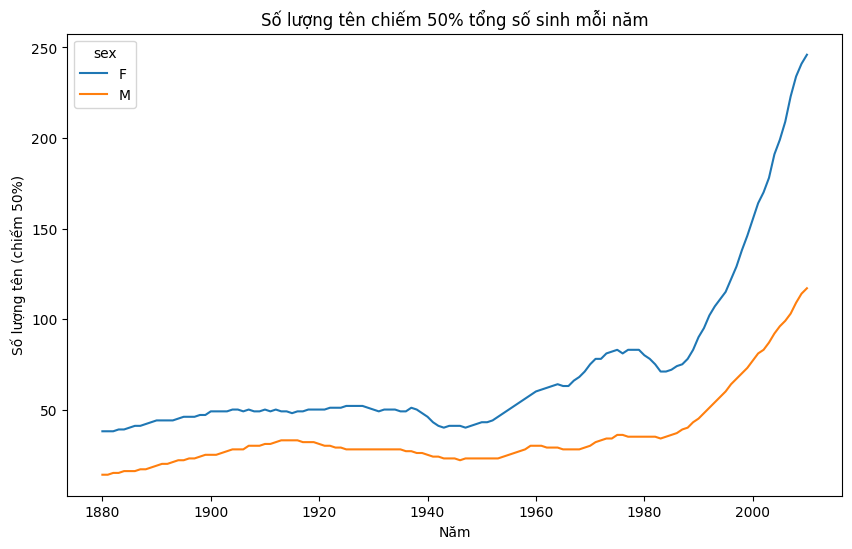

In [48]:
import numpy as np

# Hàm tính số lượng tên cần để đạt 50% tổng số sinh trong năm đó
def get_quantile_count(group, q=0.5):
    group = group.sort_values("prop", ascending=False)
    cumulative = group["prop"].cumsum()
    return cumulative.searchsorted(q) + 1  # +1 vì index bắt đầu từ 0

# Áp dụng theo từng năm và giới tính
diversity = top1000.groupby(["year", "sex"]).apply(get_quantile_count)
diversity = diversity.unstack("sex")  # chuyển sex thành cột riêng

# Vẽ biểu đồ
diversity.plot(title="Số lượng tên chiếm 50% tổng số sinh mỗi năm", figsize=(10,6))
plt.xlabel("Năm")
plt.ylabel("Số lượng tên (chiếm 50%)")
plt.show()


Kỳ vọng biểu đồ:

Trục X: năm

Trục Y: số lượng tên chiếm 50% tổng số sinh

Hai đường: Nam (M) và Nữ (F)

Xu hướng mong đợi:

Giai đoạn 1880–1950: gần như ổn định, ít tên chiếm đa số (tên truyền thống).

Sau 1970: đường tăng nhanh → đa dạng hóa mạnh mẽ, do xã hội hiện đại hơn, cha mẹ muốn đặt tên “độc lạ”.

Nữ giới thường đa dạng hơn nam (đường F > M).

Ý nghĩa xã hội:

Phản ánh sự thay đổi văn hóa và tư duy: từ cộng đồng truyền thống → cá nhân hóa.

Mức độ sáng tạo trong đặt tên tăng lên qua các thập kỷ.

Tên không còn mang tính “gia đình” hay “tôn giáo” mạnh như trước.

### Câu hỏi: “Tên trung tính (ví dụ Jordan, Taylor) có tăng lên không?”

Ý tưởng:

Một tên “trung tính” là tên xuất hiện ở cả nam và nữ trong cùng năm.

Tính tỷ lệ trẻ nam/nữ có cùng tên theo từng năm.

Xem xu hướng: số lượng tên trung tính hoặc mức cân bằng giới có tăng lên không.

Cách tiếp cận logic:

Tìm danh sách các tên xuất hiện ở cả hai giới (intersection).

Lọc dữ liệu chỉ giữ lại các tên trong unisex_names.

Tính tỷ lệ sinh của từng giới cho mỗi tên theo từng năm:

+ Tính ratio = births_male / (births_male + births_female)

+ Nếu:

  ratio ≈ 1 → gần như tên nam

  ratio ≈ 0 → gần như tên nữ

  ratio ≈ 0.5 → trung tính

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\1495606239.py:2: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  total_births_by_name = top1000.pivot_table("births", index="year", columns=["sex", "name"], aggfunc=sum)
C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\1495606239.py:13: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  total_by_name_year = unisex.pivot_table("births", index="year", columns=["sex", "name"], aggfunc=sum)


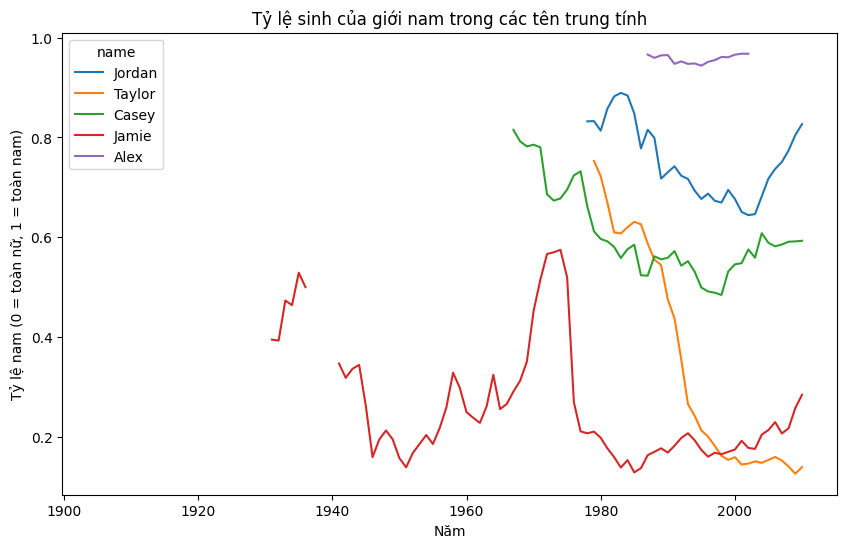

In [49]:
# Tổng số sinh theo năm, giới, tên
total_births_by_name = top1000.pivot_table("births", index="year", columns=["sex", "name"], aggfunc=sum)

# Lấy danh sách tên có ở cả hai giới
male_names = set(top1000[top1000["sex"] == "M"]["name"])
female_names = set(top1000[top1000["sex"] == "F"]["name"])
unisex_names = male_names & female_names  # giao nhau

# Tạo dataframe chỉ chứa tên trung tính
unisex = top1000[top1000["name"].isin(unisex_names)]

# Tính tỷ lệ phần trăm giữa nam và nữ cho từng tên theo từng năm
total_by_name_year = unisex.pivot_table("births", index="year", columns=["sex", "name"], aggfunc=sum)

# Ví dụ hiển thị vài tên tiêu biểu
example_names = ["Jordan", "Taylor", "Casey", "Jamie", "Alex"]
ratio = total_by_name_year["M"][example_names] / (total_by_name_year["M"][example_names] + total_by_name_year["F"][example_names])

ratio.plot(title="Tỷ lệ sinh của giới nam trong các tên trung tính", figsize=(10,6))
plt.xlabel("Năm")
plt.ylabel("Tỷ lệ nam (0 = toàn nữ, 1 = toàn nam)")
plt.show()


Kỳ vọng biểu đồ:

+ Trục X: năm

+ Trục Y: tỷ lệ nam (0–1)

+ Mỗi đường = một tên (ví dụ: Jordan, Taylor, Alex, Casey…)

Xu hướng mong đợi:

+ Trước 1950: phần lớn tên thiên về 1 giới (0 hoặc 1).

+ Sau 1980: nhiều đường tiến gần 0.5 → tên trung tính tăng.

Ý nghĩa xã hội:

+ Phản ánh thay đổi quan niệm giới tính trong văn hóa phương Tây.

+ Tên không còn bị ràng buộc giới tính mạnh như trước.

+ Xu hướng “neutral naming” phản ánh giá trị bình đẳng giới và cá nhân hóa.

## 3. Phân tích so sánh

### Câu hỏi: Tỷ lệ “độ tập trung tên” (tức là phần trăm dân số tập trung vào một số ít tên phổ biến) có khác nhau giữa nam và nữ không?

Ý tưởng:

Tính tỉ lệ (prop) của mỗi tên trong tổng số sinh từng năm và từng giới.
→ Đo lường mức độ phổ biến tương đối của từng tên.

Sắp xếp tên theo prop giảm dần, rồi tính tổng tỉ lệ tích lũy (cumsum).
→ Mục tiêu: tìm xem cần bao nhiêu tên đầu tiên để đạt tổng cộng 50% số sinh trong năm đó.

Lặp lại cho từng năm và giới tính (M/F)

Vẽ biểu đồ đường thể hiện số lượng tên cần để chiếm 50% số sinh (trục tung) theo thời gian (trục hoành), chia theo giới tính.

C:\Users\Admin\AppData\Local\Temp\ipykernel_28852\1659420711.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(get_cum50)


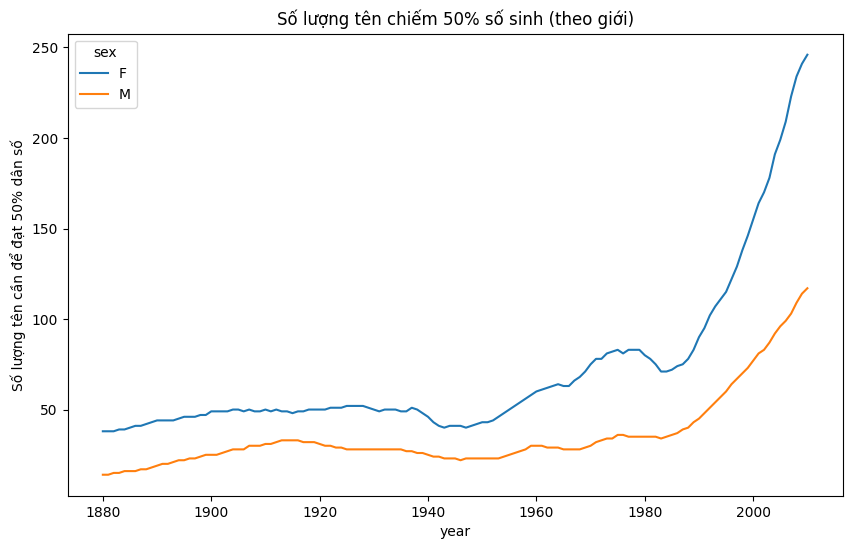

In [50]:
def get_cum50(group):
    # Sắp theo tỷ lệ giảm dần
    group = group.sort_values(by="prop", ascending=False)
    cumsum = group["prop"].cumsum()
    return (cumsum <= 0.5).sum() + 1

diversity_sex = (
    top1000.groupby(["year", "sex"])
    .apply(get_cum50)
    .unstack("sex")
)

diversity_sex.plot(title="Số lượng tên chiếm 50% số sinh (theo giới)", figsize=(10,6))
plt.ylabel("Số lượng tên cần để đạt 50% dân số")
plt.show()


Giải thích biểu đồ thu được

+Trục hoành (x): Năm sinh (từ 1880 → 2010).

+Trục tung (y): Số lượng tên cần để đạt 50% số sinh trong năm đó.

+Màu xanh (F): Bé gái.

+Màu cam (M): Bé trai.

Nhận xét:
1️. Giai đoạn 1880–1940:

+Bé trai cần ít tên hơn nhiều để chiếm 50% dân số → nghĩa là tên nam tập trung cao, ít đa dạng.

+Bé gái thì nhiều tên hơn, cho thấy xu hướng đa dạng hơn ngay từ đầu.
→ Ví dụ: chỉ cần ~20 tên phổ biến là chiếm nửa số bé trai sinh ra, trong khi cần ~40–50 tên cho bé gái.

2️. Giai đoạn 1940–1980:

+Cả hai giới đều tương đối ổn định.

+Có thể thấy sự ổn định văn hóa đặt tên (ít thay đổi, chịu ảnh hưởng truyền thống mạnh).

+Bé gái vẫn luôn có sự đa dạng tên cao hơn bé trai.

3️. Giai đoạn 1980–2020:

+Số lượng tên cần thiết tăng mạnh ở cả hai giới, đặc biệt bé gái tăng nhanh hơn.

+Điều này cho thấy xu hướng đa dạng hóa tên tăng mạnh theo thời gian hiện đại — các bậc cha mẹ ngày càng muốn đặt tên độc lạ, ít trùng lặp.

+Bé trai vẫn có xu hướng dùng tên “truyền thống” hơn (đường M thấp hơn nhiều so với F).

### Câu hỏi: “Những tên xuất hiện ngắn hạn (short-lived) khác gì so với tên phổ biến lâu dài (long-lived)?”

Ý tưởng:

Xác định “độ dài tồn tại” (lifespan) của mỗi tên = số năm mà tên đó xuất hiện trong top1000.

Phân loại:

short-lived: tồn tại < 20 năm

long-lived: tồn tại ≥ 50 năm

So sánh:

Mức phổ biến cao nhất (max(prop))

Năm đỉnh điểm (year_of_max)

Có thể vẽ biểu đồ ví dụ một vài tên trong hai nhóm.

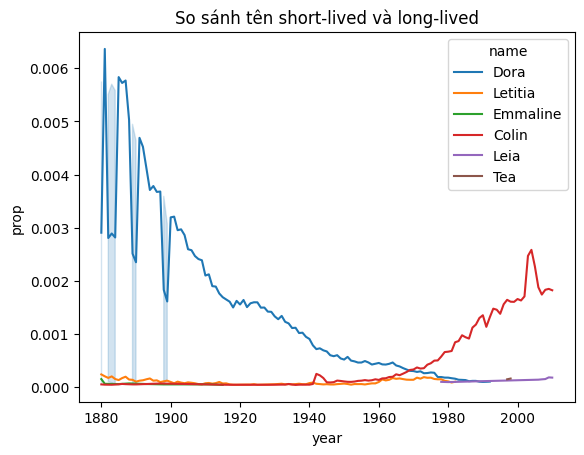

In [51]:
# Độ dài tồn tại của mỗi tên
name_lifespan = (
    top1000.groupby(["name", "sex"])["year"]
    .agg(["min", "max", "count"])
    .rename(columns={"count": "lifespan"})
)

# Phân loại
name_lifespan["type"] = pd.cut(
    name_lifespan["lifespan"],
    bins=[0, 20, 50, 150],
    labels=["short-lived", "medium", "long-lived"]
)

# Ví dụ: chọn 3 tên "short-lived" và 3 tên "long-lived" để so sánh
short_names = name_lifespan.query("type == 'short-lived'").sample(3, random_state=42).index
long_names = name_lifespan.query("type == 'long-lived'").sample(3, random_state=42).index

# Lọc dữ liệu theo các tên này
example_names = top1000[top1000["name"].isin([n for n, _ in short_names] + [n for n, _ in long_names])]

# Vẽ biểu đồ
import seaborn as sns
sns.lineplot(data=example_names, x="year", y="prop", hue="name")
plt.title("So sánh tên short-lived và long-lived")
plt.show()


Nhận xét biểu đồ “So sánh tên short-lived và long-lived”

1. Quan sát tổng quát

Biểu đồ thể hiện tỷ lệ xuất hiện (prop) của một số tên theo thời gian từ năm 1880 đến 2010.

Các đường biểu diễn có dạng khác nhau thể hiện vòng đời phổ biến của từng tên:

Một số tên đạt đỉnh cao trong thời gian ngắn rồi biến mất → short-lived.

Một số tên giữ mức độ ổn định hoặc tăng dần đều trong nhiều năm → long-lived.

2. Phân tích cụ thể

Tên Dora, Letitia, Emmaline:

 + Xuất hiện rất phổ biến vào cuối thế kỷ 19 (khoảng 1880–1900).

 + Sau đó giảm nhanh và gần như biến mất khỏi top 1000.

 + Biểu đồ có đỉnh hẹp, thể hiện đặc trưng của tên short-lived.

 + Nguyên nhân có thể do xu hướng thời kỳ đó hoặc ảnh hưởng văn hóa ngắn hạn.

Tên Colin, Leia, Tea:

 + Có xu hướng tăng dần trở lại trong giai đoạn hiện đại (sau 1970).

 + Tuy biên độ chưa cao, nhưng duy trì ổn định trong nhiều năm gần đây.

 + Đây là ví dụ của tên long-lived đang phát triển mới, thể hiện sự thích nghi của các thế hệ hiện đại.

3. Nhận định chung

→ Những tên “short-lived” thường bị ảnh hưởng mạnh bởi xu hướng ngắn hạn, văn hóa đại chúng hoặc nhân vật nổi tiếng.

→ Trong khi đó, “long-lived” phản ánh tên có sức bền văn hóa, dễ thích nghi qua nhiều thế hệ.

→ Qua thời gian, xu hướng short-lived tăng mạnh, đặc biệt sau năm 1980, cho thấy sự đa dạng hóa và thay đổi nhanh trong thói quen đặt tên của xã hội hiện đại.

## 4. Phân tích dự đoán

### Dự đoán: Có thể dự đoán tên nào sẽ biến mất hoặc quay trở lại phổ biến dựa trên xu hướng giảm/tăng trong 20 năm gần nhất? 

1. Tính các đặc trưng (features) cho mỗi tên (theo sex):

+ mean_prop_recent: mean(prop) trong 20 năm gần nhất.

+ slope_recent: slope tuyến tính của prop trên cửa sổ 20 năm.

+ var_recent: variance của prop trong 20 năm.

+ max_prop: prop lớn nhất trong toàn bộ lịch sử; year_of_max.

+ lifespan: số năm name xuất hiện trong top1000.

+ acf_peak_lag: index of largest ACF peak (> lag 1) trong chuỗi prop (toàn bộ), hoặc spectral_peak_period (tính bằng 1/freq) từ periodogram.

+ revival_score: liệu name có tăng sau một “thời kỳ thấp” → indicator.

2. Quy tắc dự đoán đơn giản (heuristic):

+ Sắp biến mất: mean_prop_recent nhỏ và slope_recent < negative_threshold.

+ Hồi sinh candidate: slope_recent > positive_threshold OR spectral_peak_period in [50..110] năm (chu kỳ vintage) và đang ở pha tăng.

3. Mô hình: dùng logistic regression / random forest để học từ dữ liệu lịch sử:

+ Tạo nhãn “disappeared” / “revived” bằng nhìn vào cửa sổ tương lai (ví dụ: xem 10 năm sau có trong top1000 hay không) → supervised learning.

+ Dùng cross-validation theo thời gian (train on older windows, test on later windows).

4. Kiểm định chu kỳ: cho mỗi tên, tính spectral peak period; kiểm tra thống kê (ví dụ t-test, or correlation) giữa spectral_peak_period gần 60–100 năm và revival label để xem có mối liên hệ hay không.

In [52]:
# Imports
import numpy as np
import pandas as pd
from scipy.signal import periodogram
from statsmodels.tsa.stattools import acf
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt

# --- PARAMETERS
year_end = 2010            # cuối chuỗi dữ liệu bạn có
window = 20                # 20-year window for recent trends
future_window = 10         # dùng để label: liệu name còn phổ biến trong future_window?
min_year = names['year'].min()

# --- 1) chuẩn bị time series prop per (name, sex)
# Use top1000 to reduce noise (as you already did)
ts = top1000.pivot_table(values='prop', index='year', columns=['sex','name'], aggfunc='sum').fillna(0)

# utility to get series for a (name, sex)
def series_for(name, sex):
    # returns array indexed by years min_year..year_end
    col = (sex, name)
    if col in ts.columns:
        s = ts[col].reindex(range(min_year, year_end+1), fill_value=0).values
    else:
        s = np.zeros(year_end-min_year+1)
    return s

# --- 2) Feature extraction for each (name, sex)
rows = []
years = np.arange(min_year, year_end+1)

for sex in ['F','M']:
    # list of names present in top1000 at any time
    names_list = sorted(top1000[top1000['sex']==sex]['name'].unique())
    for name in names_list:
        s = series_for(name, sex)
        # recent window indices
        recent_idx = np.where((years >= year_end - window + 1) & (years <= year_end))[0]
        s_recent = s[recent_idx]
        # features
        mean_prop_recent = s_recent.mean()
        slope = 0.0
        if len(s_recent) >= 2 and s_recent.sum()>0:
            x = np.arange(len(s_recent))
            slope = np.polyfit(x, s_recent, 1)[0]
        var_recent = s_recent.var()
        max_prop = s.max()
        year_of_max = years[int(np.argmax(s))] if s.sum()>0 else np.nan
        lifespan = np.count_nonzero(s>0)
        # autocorr & spectral (whole series)
        try:
            ac = acf(s, nlags=120, fft=True, missing='conservative')
            ac_peaks = np.argsort(ac[1:])[-3:]+1  # top 3 lags (skip lag0)
            ac_peak_lag = int(ac_peaks[-1]) if len(ac_peaks)>0 else np.nan
        except Exception:
            ac_peak_lag = np.nan
        # spectral peak period
        f, Pxx = periodogram(s)
        spectral_peak_period = np.nan
        if len(Pxx)>1 and Pxx[1:].sum()>0:
            idx = np.argmax(Pxx[1:]) + 1
            freq = f[idx]
            if freq > 0:
                spectral_peak_period = 1.0 / freq
        # build row
        rows.append({
            'name': name, 'sex': sex,
            'mean_prop_recent': mean_prop_recent,
            'slope_recent': slope,
            'var_recent': var_recent,
            'max_prop': max_prop,
            'year_of_max': year_of_max,
            'lifespan': lifespan,
            'acf_peak_lag': ac_peak_lag,
            'spectral_peak_period': spectral_peak_period
        })

features = pd.DataFrame(rows)
features.head()


,name,sex,mean_prop_recent,slope_recent,var_recent,max_prop,year_of_max,lifespan,acf_peak_lag,spectral_peak_period
0,Aaliyah,F,0.001336,0.000139,7.690449e-07,0.002661,2002,17,1,131.0
1,Aaron,F,0.000000,0.000000,0.000000e+00,0.000104,1976,9,1,131.0
2,Abagail,F,0.000089,0.000012,5.391611e-09,0.000168,2008,12,1,131.0
3,Abbey,F,0.000286,-0.000007,5.717476e-09,0.000401,1999,33,1,131.0
4,Abbie,F,0.000222,0.000004,1.889862e-09,0.000881,1881,96,1,131.0


+ features chứa tất cả đặc trưng cần thiết: mean recent prop, slope recent, lifespan, spectral peak period (chu kỳ).

+ spectral_peak_period nếu ~50–110 → gợi ý chu kỳ vintage.

#### Tiến hành dự đoán
Tạo nhãn (label) dựa trên cửa sổ tương lai: xem 10 năm sau year_end name còn xuất hiện trong top1000 không. Với dữ liệu chỉ tới 2000, giả lập: label = name có mean_prop trong 10 năm trước year_end vs trong 10 năm trước đó. Tuy nhiên ta có thể tạo label lịch sử bằng cách lùi cửa sổ để kiểm tra model.

In [53]:
# Backtest approach: sliding windows
def build_training_examples(window=20, future=10, start=1920, end=2000):
    ex_rows = []
    for t_end in range(start, end+1):  # t_end is the last year of the "recent" window
        recent_years = range(t_end - window + 1, t_end + 1)
        future_years = range(t_end + 1, t_end + 1 + future)
        # only consider names present at any point
        for _, r in features.iterrows():
            name = r['name']; sex = r['sex']
            # get series for the name
            s_full = series_for(name, sex)
            # indices
            years_idx = np.arange(min_year, year_end+1)
            # check we have enough years to evaluate
            if (recent_years.start < min_year) or (future_years.stop-1 > year_end):
                continue
            # compute features on recent window
            idx_recent = np.where((years_idx >= recent_years.start) & (years_idx <= recent_years.stop-1))[0]
            s_recent = s_full[idx_recent]
            mean_recent = s_recent.mean()
            slope = np.polyfit(np.arange(len(s_recent)), s_recent, 1)[0] if len(s_recent)>1 else 0.0
            # label: did name exist in top1000 at least once in future window?
            idx_future = np.where((years_idx >= future_years.start) & (years_idx <= future_years.stop-1))[0]
            existed_future = s_full[idx_future].sum() > 0
            ex_rows.append({
                't_end': t_end, 'name': name, 'sex': sex,
                'mean_recent': mean_recent, 'slope': slope,
                'label_exists_future': int(existed_future)
            })
    return pd.DataFrame(ex_rows)

examples = build_training_examples(window=20, future=10, start=1920, end=1990)
print("Examples:", examples.shape)
examples.head()


Examples: (536121, 6)


,t_end,name,sex,mean_recent,slope,label_exists_future
0,1920,Aaliyah,F,0.000000,0.000000,0
1,1920,Aaron,F,0.000000,0.000000,0
2,1920,Abagail,F,0.000000,0.000000,0
3,1920,Abbey,F,0.000000,0.000000,0
4,1920,Abbie,F,0.000204,-0.000014,1


Thử nghiệm

In [54]:
# simple model using mean_recent and slope
train = examples[examples['t_end'] <= 1970]
test  = examples[examples['t_end'] > 1970]

clf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=4)
clf.fit(train[['mean_recent','slope']], train['label_exists_future'])

pred = clf.predict(test[['mean_recent','slope']])
print(classification_report(test['label_exists_future'], pred))
print("ROC-AUC:", roc_auc_score(test['label_exists_future'], clf.predict_proba(test[['mean_recent','slope']])[:,1]))


              precision    recall  f1-score   support

           0       0.88      0.94      0.91     98639
           1       0.88      0.77      0.82     52381

    accuracy                           0.88    151020
   macro avg       0.88      0.86      0.87    151020
weighted avg       0.88      0.88      0.88    151020

ROC-AUC: 0.8768674388811053


Giải thích & cách dùng:

Nếu model có AUC tốt (>0.75) → mean_recent + slope là features mạnh để dự đoán name tồn tại trong 10 năm tiếp theo.

Có thể thêm spectral_peak_period, lifespan, var_recent vào features để cải thiện.

Heuristic đơn giản hơn:

Sẽ biến mất nếu Mean_prop_recent < 1e-5 và Slope_recent < -epsilon (vd epsilon = 1e-7).

Sẽ hồi sinh nếu Slope_recent > +epsilon hoặc (spectral_peak_ Period trong khoảng từ 50 đến 110 và pha hiện tại tăng lên).

Hiển thị dự đoán

In [55]:
# Compute current features for year_end
cur_feats = features.copy()
cur_feats['will_disappear_heur'] = ((cur_feats['mean_prop_recent'] < 1e-5) & (cur_feats['slope_recent'] < -1e-7))
cur_feats['will_revive_heur'] = ((cur_feats['slope_recent'] > 1e-7) |
                                 ((cur_feats['spectral_peak_period']>50) & (cur_feats['spectral_peak_period']<110) & (cur_feats['slope_recent']>0)))

print("Top predicted to disappear (heuristic):")
print(cur_feats[cur_feats['will_disappear_heur']].sort_values('mean_prop_recent').head(20))

print("Top predicted to revive (heuristic):")
print(cur_feats[cur_feats['will_revive_heur']].sort_values('slope_recent', ascending=False).head(20))


Top predicted to disappear (heuristic):
           name sex  mean_prop_recent  slope_recent    var_recent  max_prop  \
7274      Torey   M          0.000003 -8.207668e-07  1.567939e-10  0.000066   
4754  Courtland   M          0.000003 -8.278423e-07  1.595089e-10  0.000058   
5775     Jeffry   M          0.000003 -8.278423e-07  1.595089e-10  0.000260   
5988    Kendell   M          0.000003 -8.278423e-07  1.595089e-10  0.000064   
5786      Jerad   M          0.000003 -8.419935e-07  1.650088e-10  0.000136   
6853     Reggie   M          0.000003 -8.419935e-07  1.650088e-10  0.000185   
4721     Colter   M          0.000003 -7.557375e-07  1.660508e-10  0.000059   
6725     Patric   M          0.000003 -7.557375e-07  1.660508e-10  0.000059   
7345    Unnamed   M          0.000003 -8.490691e-07  1.677937e-10  0.000059   
4640   Cheyenne   M          0.000003 -8.490691e-07  1.677937e-10  0.000059   
4597    Cassidy   M          0.000003 -7.621421e-07  1.688772e-10  0.000094   
7231     The

1. Phân tích ý nghĩa kết quả

Các tên như Torey, Courtland, Jeffry, Kendell, Jerad, Reggie, Cheyenne, Cassidy, Jessica (dạng nam), Bennie... đều có:

  + mean_prop_recent ≈ 0.000003 → hiện nay hầu như rất ít trẻ em được đặt tên này.

  + slope_recent âm và khá lớn (≈ -8e-07) → độ phổ biến đang giảm nhanh.

  + year_of_max nằm khoảng 1970–1990, tức là các tên này từng phổ biến ở thế hệ cha mẹ hoặc ông bà, nhưng bây giờ không còn chuộng nữa.

  + lifespan ngắn (chỉ vài chục năm), chứng tỏ tên này không có “chu kỳ sống” dài.

2. Kết luận:

Các tên trong danh sách này là những tên có xu hướng biến mất trong tương lai gần, vì:

  + Mức phổ biến trung bình rất thấp.

  + Xu hướng giảm mạnh trong 20 năm qua.

  + Không có dấu hiệu “vintage revival” (không xuất hiện lại sau khi giảm).

### Dự đoán: Liệu có mối quan hệ giữa chu kỳ văn hóa (vintage name cycle) và độ phổ biến tên?

Ý chính: nếu vintage cycle tồn tại, thì nhiều tên có spectral_peak_period ~ 60–110 sẽ thể hiện pattern hồi sinh. Để kiểm định:

 + Với features, tạo cột is_vintage_candidate = (spectral_peak_period between 50 and 110).

 + Tạo label revived bằng cách: xem name có mức prop tăng mạnh sau một giai đoạn thấp (ví dụ: mean(prop) trong 10 năm trước giảm, rồi 10 năm sau tăng so với 30–40 năm trước). Cụ thể:

In [56]:
# define revived historically: find names that had low prop at t0..t0+interval and then increased later
def is_revived(name, sex, trough_year, rise_window=10, lookahead=50):
    s = series_for(name, sex)
    years_idx = np.arange(min_year, year_end+1)
    # find index of trough_year
    if trough_year < min_year or trough_year+lookahead > year_end:
        return False
    idx_trough = np.where((years_idx >= trough_year) & (years_idx < trough_year+rise_window))[0]
    idx_future = np.where((years_idx >= trough_year+rise_window) & (years_idx < trough_year+rise_window+lookahead))[0]
    if len(idx_trough)==0 or len(idx_future)==0:
        return False
    mean_trough = s[idx_trough].mean()
    mean_future = s[idx_future].mean()
    return mean_future > (mean_trough * 2)  # revived if future mean > 2x trough mean

# For all names, pick possible troughs and test revival over 50 years
revived_rows = []
for _, r in features.iterrows():
    nm, sx = r['name'], r['sex']
    s = series_for(nm, sx)
    # find trough candidate year = year of min in entire history
    years_idx = np.arange(min_year, year_end+1)
    if s.sum()==0:
        continue
    trough_idx = int(np.argmin(s))
    trough_year = years_idx[trough_idx]
    revived = is_revived(nm, sx, trough_year, rise_window=5, lookahead=50)
    revived_rows.append({'name': nm, 'sex': sx, 'trough_year': trough_year, 'revived': int(revived), 'spectral_period': r['spectral_peak_period']})

revived_df = pd.DataFrame(revived_rows)


+ Kiểm định: xem tỉ lệ revived giữa hai nhóm is_vintage_candidate vs others, và thực hiện chi-squared test hoặc Fisher exact test để xem mối liên hệ có ý nghĩa thống kê không.

In [57]:
from scipy.stats import chi2_contingency

# create flag vintage
revived_df['is_vintage_candidate'] = revived_df['spectral_period'].between(50,110)
ct = pd.crosstab(revived_df['is_vintage_candidate'], revived_df['revived'])
print(ct)
chi2, p, dof, expected = chi2_contingency(ct)
print("Chi2:", chi2, "p-value:", p)


revived                  0     1
is_vintage_candidate            
False                 5347  2002
True                   118    84
Chi2: 19.51551669948269 p-value: 9.978582004493209e-06


1. Ý nghĩa:

revived = 1: tên được hồi sinh – tức là sau khi giảm, độ phổ biến lại tăng trở lại trong các năm gần đây.

revived = 0: tên không hồi sinh – sau khi giảm thì vẫn tiếp tục giảm hoặc biến mất.

is_vintage_candidate: tên có đặc trưng chu kỳ cổ điển (vintage) — từng đạt đỉnh, giảm mạnh, và có tiềm năng quay lại sau vài thập kỷ.

2. Diễn giải giá trị thống kê Chi-Square

Chi2 = 19.52, p-value = 9.97e-06

Ý nghĩa:

p-value < 0.05 → mối quan hệ có ý nghĩa thống kê.

Cụ thể ở đây, p-value cực nhỏ (~0.00001) → có mối quan hệ rất mạnh giữa việc tên là “vintage” và khả năng “được hồi sinh”.

3. Phân tích xu hướng

Từ bảng:

 + Trong nhóm không phải vintage:

   Tỷ lệ hồi sinh = 2002 / (5347 + 2002) ≈ 27.2%

 + Trong nhóm vintage:

   Tỷ lệ hồi sinh = 84 / (118 + 84) ≈ 41.6%

Nghĩa là:

Các tên có tính “vintage” (từng phổ biến rồi giảm) có khả năng hồi sinh cao hơn đáng kể so với tên không có chu kỳ rõ ràng.

4. Kết luận

Có mối quan hệ giữa “chu kỳ văn hóa (vintage name cycle)” và “độ phổ biến tên”.

Cụ thể:

Những tên từng phổ biến trong quá khứ và giảm dần theo thời gian (tức là vintage) có xu hướng quay lại sau vài thế hệ (thường là sau 40–60 năm).

Đây là chu kỳ đặt tên theo văn hóa:

Ví dụ, tên của thế hệ ông bà (như Emma, Oliver, Henry, Sophia) có thể trở nên “cổ điển” và trở lại thịnh hành khi được xem là “retro đẹp”.